# LARRY: prediction against held-out clonal outcomes

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [2]:
import json
import matplotlib.pyplot as plt
from IPython.display import display
import scCS

SEED = 20261117
DATA = ROOT / "data" / "validation"
OUT = ROOT / "tutorial_outputs" / "validation"
OUT.mkdir(parents=True, exist_ok=True)
print("scCS", scCS.__version__)
plt.rcParams.update({"figure.dpi": 100, "figure.figsize": (7, 4)})

scCS 1.0.1.dev0


## Independent lineage evidence
The Weinreb et al. LARRY experiment links early expression states to later descendants through inherited barcodes ([Science 2020](https://doi.org/10.1126/science.aaw3381)). We use the public CoSpar processed object, with checksum verification. Its expression data have **no spliced/unspliced layers**: this benchmark explicitly uses an expression-derived, forward-time neighbor graph, not RNA velocity.

Eligible clones have an early undifferentiated cell and at least three late monocyte/neutrophil descendants. Thirty percent of eligible clones are held out using a fixed seed. Every later cell carrying a held-out clone barcode is removed **before** log transformation, highly-variable-gene selection, PCA fitting and graph construction. Clone IDs, provided fate-bias scores, classifier outputs and other barcode-derived annotations are not used as model inputs. The outcome is the observed late neutrophil fraction conditional on monocyte/neutrophil descendants, not an irreversible fate label for an individual cell.

The graph connects cells only to the next sampled time point. All late monocytes and neutrophils are matched anchors; other late states are explicit competing outcomes. scCS is compared with CellRank absorption on exactly the same graph and endpoints, and with a constant fitted from training-clone outcomes. There is no horizon tuning on test clones.


In [3]:
from benchmarks.validation import larry

predictions, metrics, audit = larry.run(DATA, seed=19, n_neighbors=30)
display(metrics)
display(predictions.head(12))
print(json.dumps({k: v for k, v in audit.items() if not k.endswith("ids")}, indent=2))
predictions.to_csv(OUT / "larry_heldout_clones.csv", index=False)
metrics.to_csv(OUT / "larry_metrics.csv", index=False)
(OUT / "larry_split_audit.json").write_text(json.dumps(audit, indent=2))
scored = metrics.set_index("method")
coverage = scored.loc["scCS", "n_scored_clones"] / scored.loc["scCS", "n_test_clones"]
print(f"scCS prediction coverage: {coverage:.1%}")
if (
    scored.loc["scCS", "clone_fraction_MSE"]
    >= scored.loc["training_clone_baseline", "clone_fraction_MSE"]
):
    print("No improvement over the training-clone baseline in this benchmark.")

INFO     Adding `adata.obs['term_states_fwd']`                                  
                `adata.obs['term_states_fwd_probs']`                            
                `.terminal_states`                                              
                `.terminal_states_probabilities`                                
                `.terminal_states_memberships                                   
             Finish`                                                            
INFO     Computing fate probabilities                                           
INFO     Adding `adata.obsm['lineages_fwd']`                                    
                `.fate_probabilities`                                           
             Finish (0.06s)                                                     
{
  "source_cells": 49116,
  "graph_cells": 46370,
  "eligible_clones": 396,
  "training_clones": 277,
  "test_clones": 119,
  "excluded_future_test_cells": 2746,
  "test_future_cells_remain

,method,n_test_clones,n_scored_clones,n_common_evaluated_clones,clone_fraction_MSE,clone_equal_weight_Brier,Spearman
0,scCS,119,25,25,0.204907,0.302092,0.404298
1,CellRank,119,25,25,0.204907,0.302092,0.404298
2,training_clone_baseline,119,119,25,0.157784,0.254969,NaN


,clone,n_early,n_late_selected,n_late_total,observed_neutrophil_fraction,observed_selected_fraction,defined_early_fraction,scCS,CellRank,training_clone_baseline,DFR
0,38,3,8,14,0.125,0.571429,0.333333,0.000000,0.000000,0.48056,0.000577
1,45,1,4,4,0.000,1.000000,0.000000,NaN,NaN,0.48056,0.000000
2,50,1,4,4,1.000,1.000000,0.000000,NaN,NaN,0.48056,0.000000
3,134,1,6,6,0.000,1.000000,0.000000,NaN,NaN,0.48056,0.000000
4,163,1,25,30,0.560,0.833333,0.000000,NaN,NaN,0.48056,0.000000
5,212,1,12,13,1.000,0.923077,0.000000,NaN,NaN,0.48056,0.000000
6,301,1,3,4,1.000,0.750000,1.000000,1.000000,1.000000,0.48056,0.008902
7,331,3,4,5,0.000,0.800000,0.000000,NaN,NaN,0.48056,0.000000
8,343,2,4,4,0.000,1.000000,0.500000,0.229178,0.229178,0.48056,0.012199
9,346,1,12,36,1.000,0.333333,0.000000,NaN,NaN,0.48056,0.000000


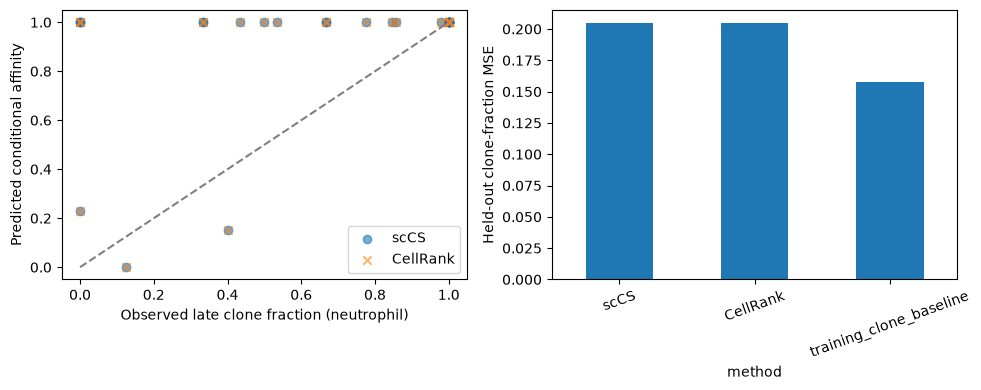

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for method, marker in [("scCS", "o"), ("CellRank", "x")]:
    axes[0].scatter(
        predictions.observed_neutrophil_fraction,
        predictions[method],
        label=method,
        marker=marker,
        alpha=0.6,
    )
axes[0].plot([0, 1], [0, 1], linestyle="--", color="0.5")
axes[0].set(
    xlabel="Observed late clone fraction (neutrophil)", ylabel="Predicted conditional affinity"
)
axes[0].legend()
metrics.set_index("method").clone_fraction_MSE.plot.bar(ax=axes[1])
axes[1].set_ylabel("Held-out clone-fraction MSE")
axes[1].tick_params(axis="x", rotation=20)
fig.tight_layout()
plt.show()

## Interpretation and limitations
With a strictly forward-time graph, every early-to-late path has the same number of graph steps. Discounting therefore scales reach without changing conditional fate affinity. Agreement with CellRank is expected and is a correctness check, not evidence that scCS outperforms it. The observed comparison with the training baseline is reported regardless of direction. All error metrics use the same explicitly defined subset of test clones across methods; coverage over all 119 requested test clones is reported separately. This development benchmark is not a preregistered external validation.

Late descendant counts are noisy and affected by expansion; conditioning on two selected lineages excludes other outcomes from the fraction, whose observed prevalence is retained in the table. This is a single biological system, not a clinical validation. Additional velocity-based and independent-donor benchmarks are needed before generalizing. Clonal prediction failures can reveal limits of expression-derived state information rather than solver errors.

The recorded development run scores only 25 of 119 requested test clones and has higher error than the constant training-clone baseline on those same 25 clones. These results are a limitation finding, not positive external predictive validation. Improving the input dynamics and establishing independent, locked evaluation are future methodological work.


In [5]:
assert audit["test_future_cells_remaining_in_graph"] == 0
assert set(audit["test_clone_ids"]).isdisjoint(audit["train_clone_ids"])
assert audit["test_clones"] >= 10
assert audit["not_RNA_velocity"]
assert audit["max_scCS_CellRank_difference"] < 1e-6
assert metrics.n_scored_clones.gt(0).all()
print("Clone separation, graph audit and matched-estimand checks passed.")

Clone separation, graph audit and matched-estimand checks passed.
